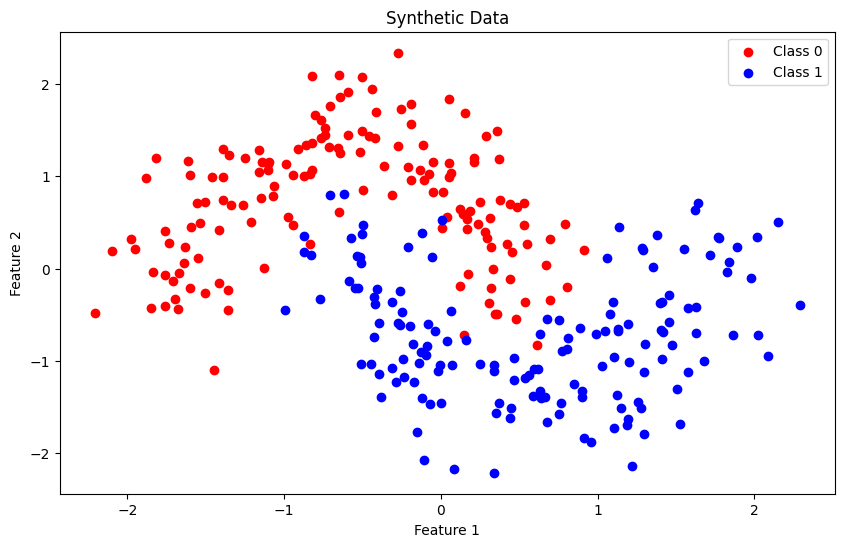

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Generate synthetic data
X, y = make_moons(n_samples=300, noise=0.2, random_state=42)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

# Plot the dataset
plt.figure(figsize=(10, 6))
plt.scatter(X_scaled[y == 0][:, 0], X_scaled[y == 0][:, 1], color='red', label='Class 0')
plt.scatter(X_scaled[y == 1][:, 0], X_scaled[y == 1][:, 1], color='blue', label='Class 1')
plt.title('Synthetic Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()


In [4]:
from sklearn.decomposition import KernelPCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

# Apply Kernel PCA with Polynomial Kernel
kpca = KernelPCA(kernel='poly', degree=3, coef0=1, n_components=2)
X_kpca_train = kpca.fit_transform(X_train)
X_kpca_test = kpca.transform(X_test)

# Train SVM classifier on the KPCA-transformed data
svm = SVC(kernel='linear')
svm.fit(X_kpca_train, y_train)

# Make predictions and evaluate the model
y_pred = svm.predict(X_kpca_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")

# Plot decision boundary
xx, yy = np.meshgrid(np.linspace(X_scaled[:, 0].min(), X_scaled[:, 0].max(), 500),
                     np.linspace(X_scaled[:, 1].min(), X_scaled[:, 1].max(), 500))
Z = svm.predict(kpca.transform(np.c_[xx.ravel(), yy.ravel()]))
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.Paired)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolor='k', cmap=plt.cm.Paired)
plt.title('SVM Decision Boundary with Kernel PCA')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


Accuracy: 0.93


ValueError: X has 2 features, but KernelPCA is expecting 3 features as input.

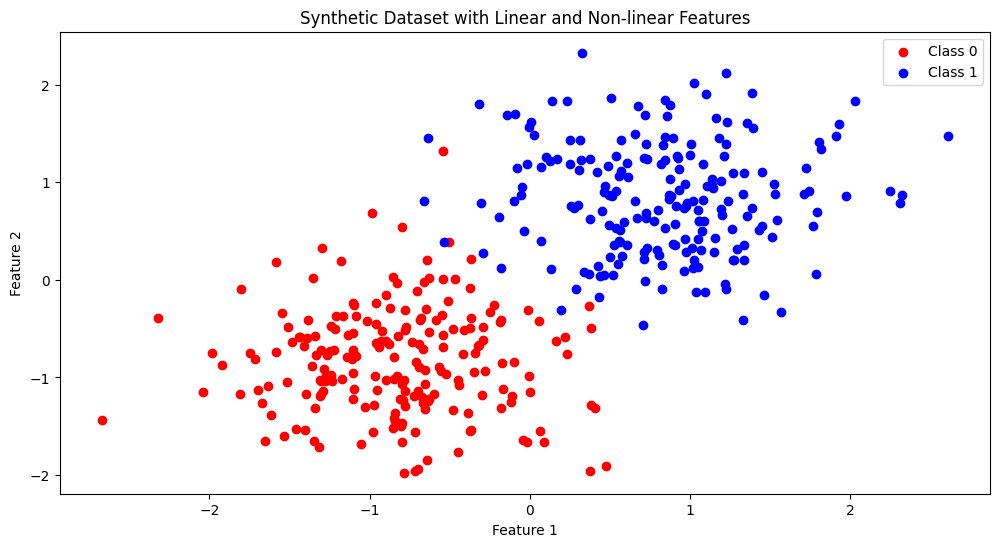

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Seed for reproducibility
np.random.seed(42)

# Number of samples
n_samples = 200

# Generate linearly separable features
X1 = np.random.randn(n_samples, 2)
X2 = np.random.randn(n_samples, 2) + np.array([3, 3])

# Generate labels
y1 = np.zeros(n_samples)
y2 = np.ones(n_samples)

# Combine the datasets
X_linear = np.vstack([X1, X2])
y_linear = np.concatenate([y1, y2])

# Introduce non-linearity by adding a non-linear feature
# Feature 3: Non-linear (e.g., a sine function of the first feature)
non_linear_feature = np.sin(X_linear[:, 0]) * np.cos(X_linear[:, 1]) + X_linear[:, 0]**2 - X_linear[:, 1]**3

# Combine all features
X = np.hstack([X_linear, non_linear_feature.reshape(-1, 1)])

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_linear, test_size=0.3, random_state=42)

# Plot the dataset (only the first two features for visualization)
plt.figure(figsize=(12, 6))
plt.scatter(X_scaled[y_linear == 0][:, 0], X_scaled[y_linear == 0][:, 1], c='red', label='Class 0')
plt.scatter(X_scaled[y_linear == 1][:, 0], X_scaled[y_linear == 1][:, 1], c='blue', label='Class 1')
plt.title('Synthetic Dataset with Linear and Non-linear Features')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()


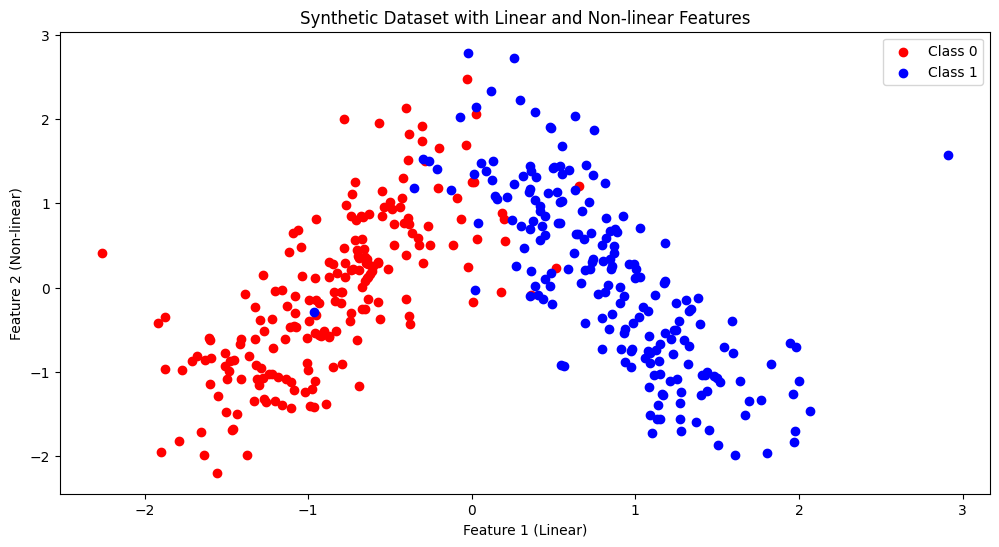

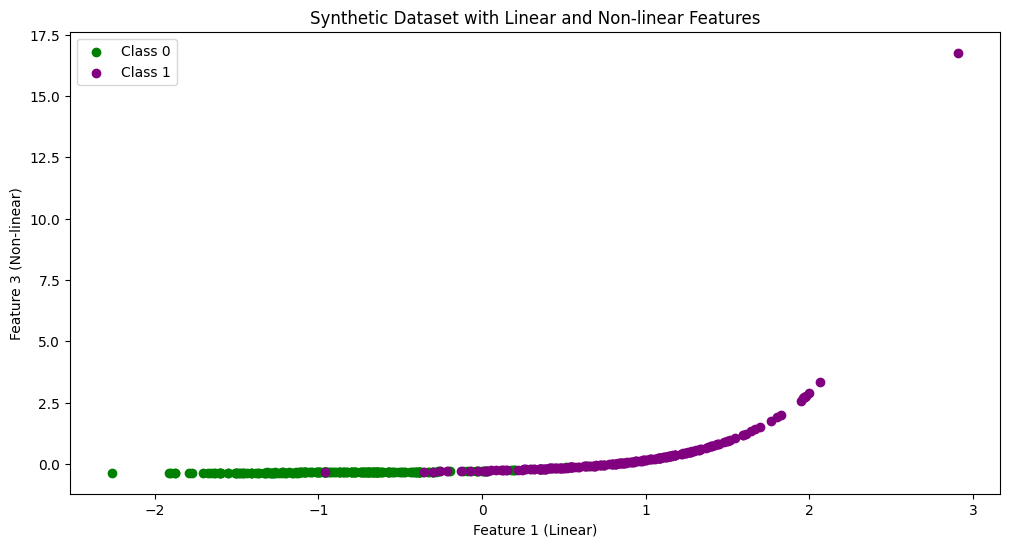

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Seed for reproducibility
np.random.seed(42)

# Number of samples
n_samples = 200

# Generate a single linear feature (e.g., normally distributed data)
X_linear = np.random.randn(n_samples, 1)

# Generate labels
y1 = np.zeros(n_samples)
y2 = np.ones(n_samples)

# Generate another linear feature for separation
X_separation = np.random.randn(n_samples, 1) + 3

# Combine to make one linear feature (Feature 1)
X_combined_linear = np.vstack([X_linear, X_separation])

# Now introduce non-linearity by adding two non-linear features
# Feature 2: Non-linear (e.g., a sine function of the linear feature)
non_linear_feature_1 = np.sin(X_combined_linear[:, 0]) + 0.5 * np.random.randn(2 * n_samples)

# Feature 3: Another non-linear feature (e.g., exponential of the linear feature)
non_linear_feature_2 = np.exp(X_combined_linear[:, 0]) + 0.1 * np.random.randn(2 * n_samples)

# Combine all features into a single dataset
X = np.hstack([X_combined_linear, non_linear_feature_1.reshape(-1, 1), non_linear_feature_2.reshape(-1, 1)])

# Combine the labels for the two classes
y = np.concatenate([y1, y2])

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

# Plot the dataset (only the first two features for visualization)
plt.figure(figsize=(12, 6))
plt.scatter(X_scaled[y == 0][:, 0], X_scaled[y == 0][:, 1], c='red', label='Class 0')
plt.scatter(X_scaled[y == 1][:, 0], X_scaled[y == 1][:, 1], c='blue', label='Class 1')
plt.title('Synthetic Dataset with Linear and Non-linear Features')
plt.xlabel('Feature 1 (Linear)')
plt.ylabel('Feature 2 (Non-linear)')
plt.legend()
plt.show()

# Optionally, plot the non-linear features separately
plt.figure(figsize=(12, 6))
plt.scatter(X_scaled[y == 0][:, 0], X_scaled[y == 0][:, 2], c='green', label='Class 0')
plt.scatter(X_scaled[y == 1][:, 0], X_scaled[y == 1][:, 2], c='purple', label='Class 1')
plt.title('Synthetic Dataset with Linear and Non-linear Features')
plt.xlabel('Feature 1 (Linear)')
plt.ylabel('Feature 3 (Non-linear)')
plt.legend()
plt.show()


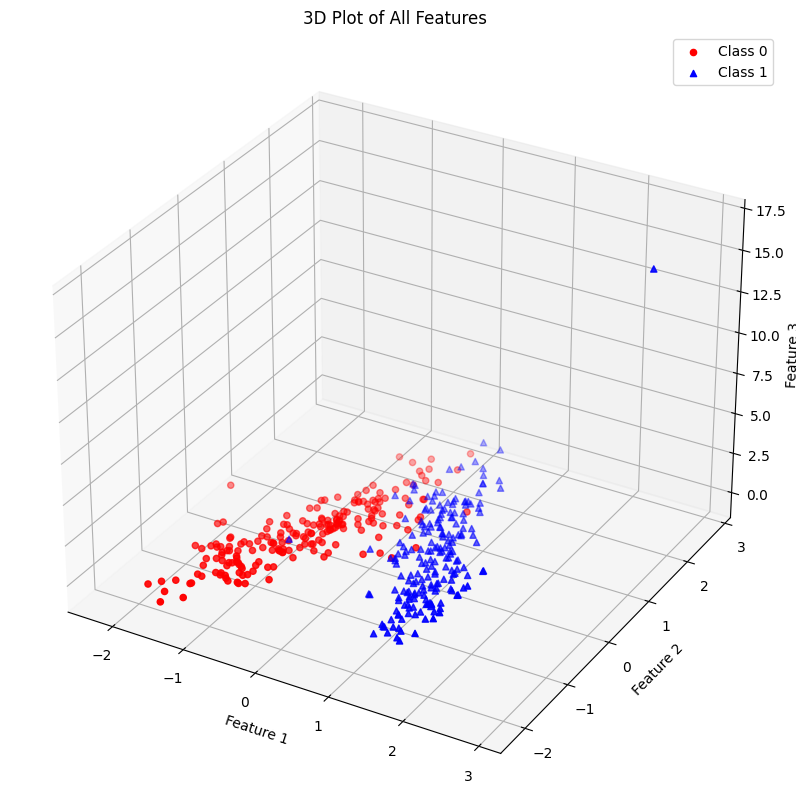

In [7]:
# 3D Plot for all features
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot each class
scatter = ax.scatter(X_scaled[y_linear == 0][:, 0], X_scaled[y_linear == 0][:, 1], X_scaled[y_linear == 0][:, 2], c='red', label='Class 0', marker='o')
scatter = ax.scatter(X_scaled[y_linear == 1][:, 0], X_scaled[y_linear == 1][:, 1], X_scaled[y_linear == 1][:, 2], c='blue', label='Class 1', marker='^')

# Labels and title
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')
ax.set_title('3D Plot of All Features')
ax.legend()

plt.show()

linear [[-0.57213509  0.30747783]
 [-0.87125293 -0.57851796]
 [-0.65919827  0.46154268]
 [ 0.03818229  0.77125091]
 [-1.12763065 -0.22084125]
 [-0.37936204 -0.43247074]
 [ 1.61092742 -1.9842534 ]
 [ 0.847391    0.34370782]
 [ 0.20417196  0.55422517]
 [ 0.62354545  0.40693051]
 [ 1.40548158 -1.03503999]
 [-0.40410875  0.38772334]
 [ 1.04816441 -0.22497125]
 [-0.03765142  1.68956035]
 [-0.42041539  1.30132998]
 [-0.73615815  0.8550276 ]
 [ 1.17679512  0.05820358]
 [ 0.1252973   1.2746946 ]
 [ 0.54124133  1.02024063]
 [ 0.4832988   1.89356397]
 [-0.71669119  1.25630712]
 [-1.50214608 -1.47847078]
 [ 0.53707469  1.43943546]
 [-1.22035841 -1.02913564]
 [-1.31283375 -1.08626479]
 [ 1.96972836 -1.83373979]
 [-0.29842205  0.29418262]
 [-0.84510322 -0.0465583 ]
 [-0.60544249  0.25540061]
 [ 1.02519222 -0.35439903]
 [ 0.0309136   0.58198168]
 [ 0.43660433 -0.13076255]
 [ 1.05813941 -0.83842381]
 [-0.69398003  0.36957528]
 [-1.08345954 -0.09459328]
 [-0.71383785  0.56474121]
 [-1.26832705 -0.5149

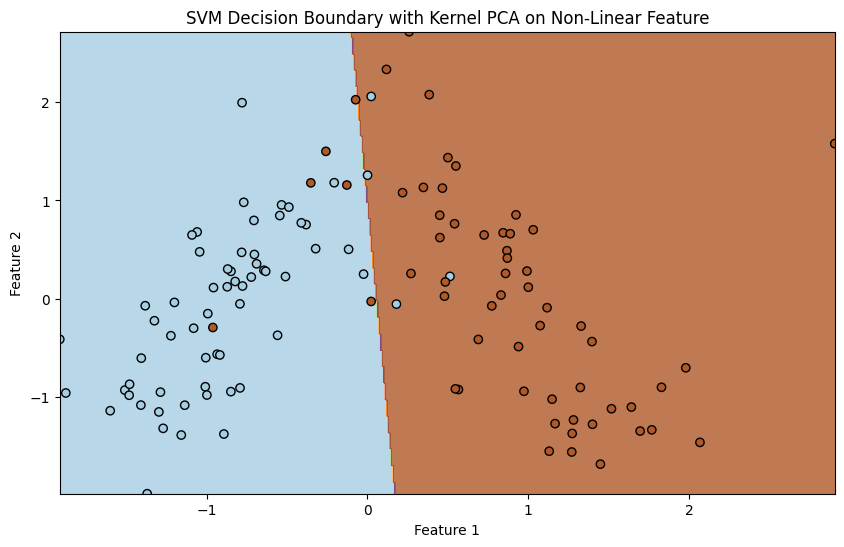

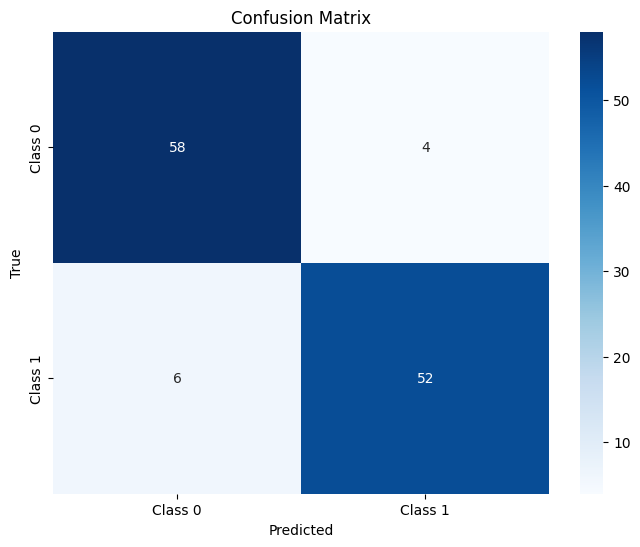

In [8]:
from sklearn.decomposition import KernelPCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Separate the linear and non-linear features
X_linear_train = X_train[:, :2]  # Feature 1 and Feature 2 (linearly separable)
X_linear_test = X_test[:, :2]
print("linear", X_linear_train)

X_nonlinear_train = X_train[:, 2].reshape(-1, 1)  # Feature 3 (non-linear)
X_nonlinear_test = X_test[:, 2].reshape(-1, 1)
print("nonlinear", X_nonlinear_train)

# Apply Kernel PCA with a polynomial kernel to the non-linear feature
kpca = KernelPCA(kernel='poly', degree=3, coef0=1, n_components=1)
X_kpca_train = kpca.fit_transform(X_nonlinear_train)
X_kpca_test = kpca.transform(X_nonlinear_test)
print("kpca", X_kpca_train)

# Combine the KPCA-transformed feature with the linear features
X_combined_train = np.hstack([X_linear_train, X_kpca_train])
X_combined_test = np.hstack([X_linear_test, X_kpca_test])
print("combined", X_combined_train)

# Train SVM classifier on the combined data
svm = SVC(kernel='linear')
svm.fit(X_combined_train, y_train)

# Make predictions and evaluate the model
y_pred = svm.predict(X_combined_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")

# Plot decision boundary
xx, yy = np.meshgrid(np.linspace(X_combined_test[:, 0].min(), X_combined_test[:, 0].max(), 500),
                     np.linspace(X_combined_test[:, 1].min(), X_combined_test[:, 1].max(), 500))
Z = svm.predict(np.c_[xx.ravel(), yy.ravel(), kpca.transform(np.c_[xx.ravel()]).ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.Paired)
plt.scatter(X_combined_test[:, 0], X_combined_test[:, 1], c=y_test, edgecolor='k', cmap=plt.cm.Paired)
plt.title('SVM Decision Boundary with Kernel PCA on Non-Linear Feature')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


Linear Feature (Train): [[-0.57213509]
 [-0.87125293]
 [-0.65919827]
 [ 0.03818229]
 [-1.12763065]
 [-0.37936204]
 [ 1.61092742]
 [ 0.847391  ]
 [ 0.20417196]
 [ 0.62354545]
 [ 1.40548158]
 [-0.40410875]
 [ 1.04816441]
 [-0.03765142]
 [-0.42041539]
 [-0.73615815]
 [ 1.17679512]
 [ 0.1252973 ]
 [ 0.54124133]
 [ 0.4832988 ]
 [-0.71669119]
 [-1.50214608]
 [ 0.53707469]
 [-1.22035841]
 [-1.31283375]
 [ 1.96972836]
 [-0.29842205]
 [-0.84510322]
 [-0.60544249]
 [ 1.02519222]
 [ 0.0309136 ]
 [ 0.43660433]
 [ 1.05813941]
 [-0.69398003]
 [-1.08345954]
 [-0.71383785]
 [-1.26832705]
 [-0.6358128 ]
 [ 1.17808003]
 [ 0.74354711]
 [ 0.38740273]
 [ 1.08702354]
 [ 0.72322767]
 [-0.96451179]
 [ 0.7187795 ]
 [-0.55062129]
 [ 0.9060589 ]
 [-1.27836807]
 [-1.55102386]
 [ 0.41579566]
 [-1.21364896]
 [-1.18258853]
 [-1.59542925]
 [-0.66908762]
 [-0.72990992]
 [ 1.43785172]
 [-0.68821761]
 [ 0.44499242]
 [-0.63334499]
 [-1.60792095]
 [-1.89975182]
 [-0.68885727]
 [-0.0653329 ]
 [-1.4148722 ]
 [-0.2831531 ]
 

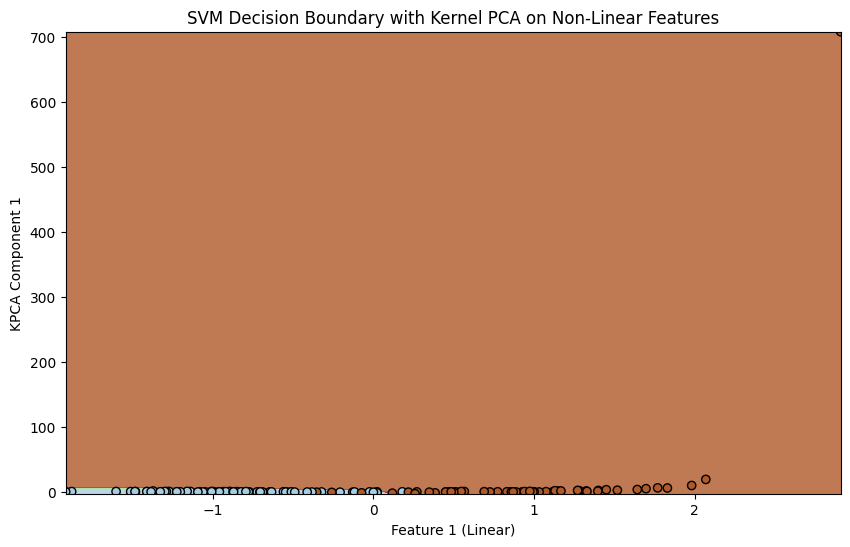

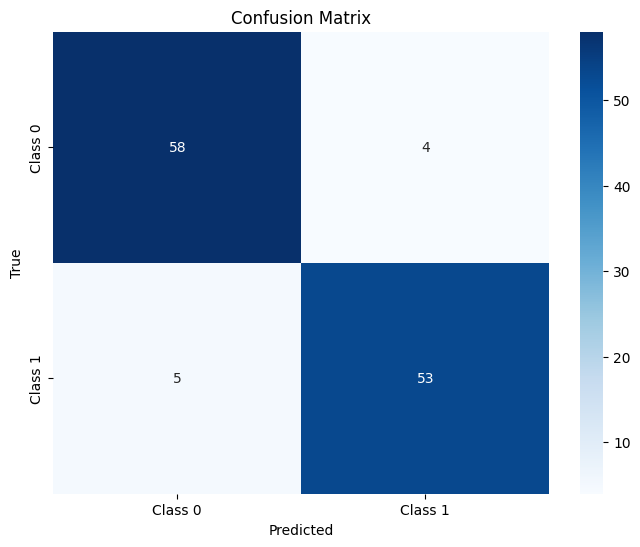

In [16]:
from sklearn.decomposition import KernelPCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Separate the linear and non-linear features
X_linear_train = X_train[:, 0].reshape(-1, 1)  # Feature 1 (linearly separable)
X_linear_test = X_test[:, 0].reshape(-1, 1)
print("Linear Feature (Train):", X_linear_train)

X_nonlinear_train = X_train[:, 1:]  # Feature 2 and Feature 3 (non-linear)
X_nonlinear_test = X_test[:, 1:]
print("Non-linear Features (Train):", X_nonlinear_train)

# Apply Kernel PCA with a polynomial kernel to the non-linear features
kpca = KernelPCA(kernel='poly', degree=3, coef0=1, n_components=2)
X_kpca_train = kpca.fit_transform(X_nonlinear_train)
X_kpca_test = kpca.transform(X_nonlinear_test)
print("KPCA Transformed Features (Train):", X_kpca_train)

# Combine the KPCA-transformed non-linear features with the linear feature
X_combined_train = np.hstack([X_linear_train, X_kpca_train])
X_combined_test = np.hstack([X_linear_test, X_kpca_test])
print("Combined Features (Train):", X_combined_train)

# Train SVM classifier on the combined data
svm = SVC(kernel='linear')
svm.fit(X_combined_train, y_train)

# Make predictions and evaluate the model
y_pred = svm.predict(X_combined_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")

# Plot decision boundary
xx, yy = np.meshgrid(np.linspace(X_combined_test[:, 0].min(), X_combined_test[:, 0].max(), 500),
                     np.linspace(X_combined_test[:, 1].min(), X_combined_test[:, 1].max(), 500))

# We need to calculate the third feature (second KPCA component) for the entire grid
zz = np.zeros(xx.shape)
grid = np.c_[xx.ravel(), yy.ravel(), zz.ravel()]
transformed_grid = kpca.transform(grid[:, 1:])

# Rebuild the grid to include the linear feature and the KPCA components
final_grid = np.hstack([grid[:, 0].reshape(-1, 1), transformed_grid])

# Predict using the trained SVM model
Z = svm.predict(final_grid)
Z = Z.reshape(xx.shape)

# Plot the decision boundary
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.Paired)
plt.scatter(X_combined_test[:, 0], X_combined_test[:, 1], c=y_test, edgecolor='k', cmap=plt.cm.Paired)
plt.title('SVM Decision Boundary with Kernel PCA on Non-Linear Features')
plt.xlabel('Feature 1 (Linear)')
plt.ylabel('KPCA Component 1')
plt.show()

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()



Accuracy: 0.92


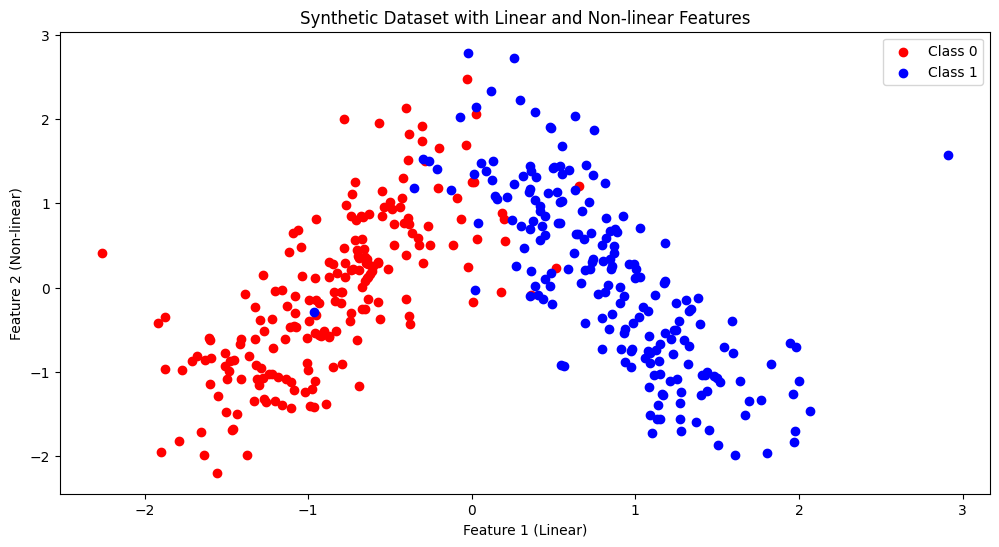

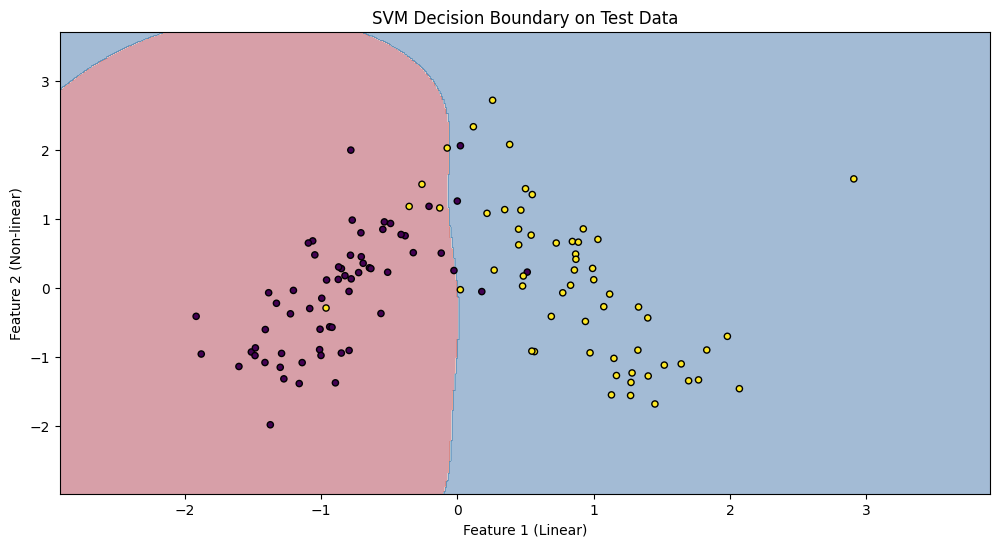

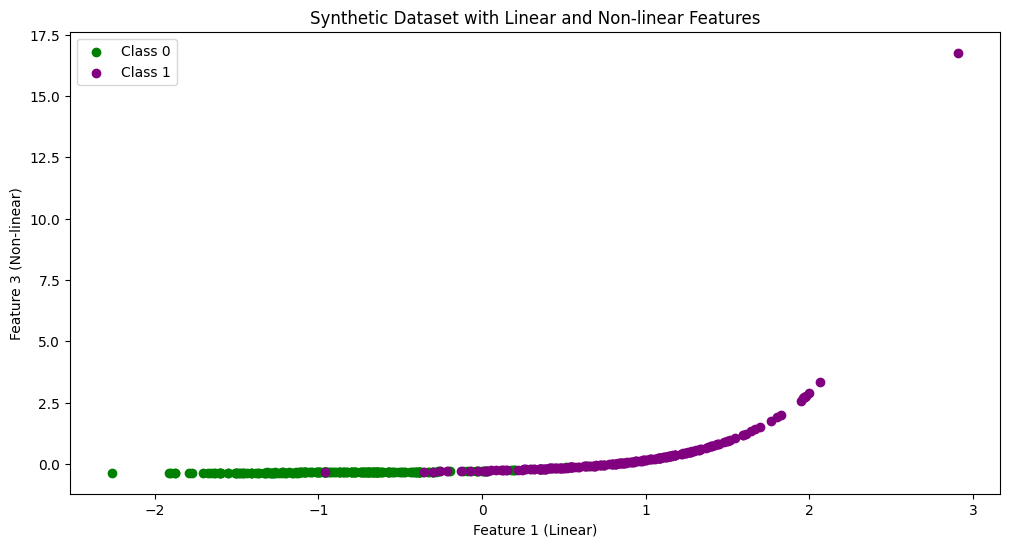

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Seed for reproducibility
np.random.seed(42)

# Number of samples
n_samples = 200

# Generate a single linear feature (e.g., normally distributed data)
X_linear = np.random.randn(n_samples, 1)

# Generate labels
y1 = np.zeros(n_samples)
y2 = np.ones(n_samples)

# Generate another linear feature for separation
X_separation = np.random.randn(n_samples, 1) + 3

# Combine to make one linear feature (Feature 1)
X_combined_linear = np.vstack([X_linear, X_separation])

# Now introduce non-linearity by adding two non-linear features
# Feature 2: Non-linear (e.g., a sine function of the linear feature)
non_linear_feature_1 = np.sin(X_combined_linear[:, 0]) + 0.5 * np.random.randn(2 * n_samples)

# Feature 3: Another non-linear feature (e.g., exponential of the linear feature)
non_linear_feature_2 = np.exp(X_combined_linear[:, 0]) + 0.1 * np.random.randn(2 * n_samples)

# Combine all features into a single dataset
X = np.hstack([X_combined_linear, non_linear_feature_1.reshape(-1, 1), non_linear_feature_2.reshape(-1, 1)])

# Combine the labels for the two classes
y = np.concatenate([y1, y2])

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

# Initialize the SVM with an RBF kernel
svm = SVC(kernel='rbf', random_state=42)

# Train the SVM on the training data
svm.fit(X_train, y_train)

# Predict on the test set
y_pred = svm.predict(X_test)

# Evaluate the performance of the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

# Plot the dataset (only the first two features for visualization)
plt.figure(figsize=(12, 6))
plt.scatter(X_scaled[y == 0][:, 0], X_scaled[y == 0][:, 1], c='red', label='Class 0')
plt.scatter(X_scaled[y == 1][:, 0], X_scaled[y == 1][:, 1], c='blue', label='Class 1')
plt.title('Synthetic Dataset with Linear and Non-linear Features')
plt.xlabel('Feature 1 (Linear)')
plt.ylabel('Feature 2 (Non-linear)')
plt.legend()
plt.show()

# Plot the decision boundary for the first two features
def plot_decision_boundary(clf, X, y, ax, feature_indices=(0, 1)):
    x_min, x_max = X[:, feature_indices[0]].min() - 1, X[:, feature_indices[0]].max() + 1
    y_min, y_max = X[:, feature_indices[1]].min() - 1, X[:, feature_indices[1]].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                         np.arange(y_min, y_max, 0.01))

    # We create a 4D input array where the non-plotted features are set to their mean value
    grid = np.zeros((xx.ravel().shape[0], X.shape[1]))
    grid[:, feature_indices[0]] = xx.ravel()
    grid[:, feature_indices[1]] = yy.ravel()

    Z = clf.predict(grid)
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.RdBu)
    ax.scatter(X[:, feature_indices[0]], X[:, feature_indices[1]], c=y, s=20, edgecolor='k')

fig, ax = plt.subplots(figsize=(12, 6))
plot_decision_boundary(svm, X_test, y_test, ax)
plt.title('SVM Decision Boundary on Test Data')
plt.xlabel('Feature 1 (Linear)')
plt.ylabel('Feature 2 (Non-linear)')
plt.show()

# Optional: Plot the non-linear features separately
plt.figure(figsize=(12, 6))
plt.scatter(X_scaled[y == 0][:, 0], X_scaled[y == 0][:, 2], c='green', label='Class 0')
plt.scatter(X_scaled[y == 1][:, 0], X_scaled[y == 1][:, 2], c='purple', label='Class 1')
plt.title('Synthetic Dataset with Linear and Non-linear Features')
plt.xlabel('Feature 1 (Linear)')
plt.ylabel('Feature 3 (Non-linear)')
plt.legend()
plt.show()
